# Case 1 — notebook_5: Anchor Linear + Bobot Per-Subset

`notebook_3` = **LB 0,1996** (terbaik). `notebook_4` diprediksi seri di 0,199 dan tidak jadi
disubmit. Notebook ini menguji **12 batch ide baru** untuk mengejar peringkat 1 di 0,18.

**Dua berhasil, sepuluh gagal.** Hasil bersihnya `lb_est` 0,1984 → **0,1908**
(estimasi jujur setelah koreksi optimisme seleksi: **≈0,1932**, prediksi LB **≈0,194**).

**0,18 tidak tercapai, dan notebook ini menunjukkan kenapa dengan bukti kuantitatif,
bukan dugaan.** Lihat §7.

## Yang diuji

| # | Ide | Hasil | Dipakai? |
|---|---|---|---|
| 1 | Kuantisasi `depth_km` di input model | lb_est 0,1999 vs 0,1991 | ❌ |
| 2 | Buang depth dari fitur sepenuhnya | 0,2030 | ❌ |
| 3 | Buang `grp_size` | 0,1997 | ❌ |
| 4 | Importance weighting komposisi (global) | 0,1999 | ❌ (dipakai parsial, lihat §4) |
| 5 | Snapping prediksi ke grid 0,1 | 0,1994 vs 0,1990 | ❌ |
| 6 | Smoothing depth bulat-**dalam** (≥100 km) | **0,1984** | ✅ |
| 7 | Klasifikasi ordinal 32 kelas + weighted median | 0,2542 | ❌ |
| 8 | Pooling posterior antar-record | 0,2636 | ❌ |
| 9 | **Target residual relasi EEW (ridge anchor)** | **0,1955** | ✅ |
| 10 | `linear_tree=True` | 0,2024 | ❌ |
| 11 | Anchor sebagai fitur (bukan target residual) | 0,2015 | ❌ |
| 12 | **Bobot blend terpisah per subset** | **0,1908** | ✅ |
| 13 | Smoothing adaptif per ukuran grup | 0,2260 (nol) | ❌ |
| 14 | Smoothing-kNN di ruang prediksi | 0,2252 (derau) | ❌ |
| 15 | MLP di ruang fitur | divergen (0,778) | ❌ |

## Riwayat leaderboard

| Submission | CV | Estimasi | **LB aktual** | Meleset |
|---|---|---|---|---|
| notebook_1 | 0,1826 | 0,1953 | **0,2005** | +0,0052 |
| notebook_2 | 0,1789 | 0,1902 | **0,2262** ❌ | +0,0360 |
| notebook_3 | 0,1852 | 0,1986 | **0,1996** ✅ | +0,0010 |
| notebook_4 | 0,1850 | 0,1983 | tidak disubmit | — |
| notebook_5 (ini) | 0,1791 | 0,1908 → jujur 0,1932 | ? | — |


---
## 1. Setup, Fitur, Metrik

Identik dengan notebook_3/4 supaya angkanya bisa dibandingkan langsung.


In [1]:
import numpy as np, pandas as pd, time, sys, warnings, json, pickle
warnings.filterwarnings("ignore")
from pathlib import Path
from scipy import signal, stats
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"]=110; pd.set_option("display.width",200)

DATA=Path("seismic-dataset"); SUB=Path("submission"); SUB.mkdir(exist_ok=True)
FS,P_IDX,EPS=200,200,1e-15
train=(pd.read_csv(DATA/"train"/"train_meta.csv")
         .merge(pd.read_csv(DATA/"train"/"train_labels.csv"),on="sample_id"))
test=pd.read_csv(DATA/"test"/"test_meta.csv")
y=train.magnitude.values.astype(np.float64)
ev=train.groupby(["depth_km","magnitude"]).ngroup().values
cnt=pd.Series(ev).map(pd.Series(ev).value_counts()).values
def mag_weight(m):
    m=np.asarray(m); return np.where(m<5.5,1.0,np.where(m<6.0,1.5,np.where(m<6.5,2.0,2.5)))
def eb_twmae(yt,yp,e):
    df=pd.DataFrame({"y":yt,"p":yp,"e":e}); df["err"]=np.abs(df.y-df.p)
    g=df.groupby("e").agg(mae=("err","mean"),m=("y","first"))
    w=mag_weight(g.m.values); return float((w*g.mae.values).sum()/w.sum())
SW=mag_weight(y)/cnt
d_tr=train.depth_km.values; d_te=test.depth_km.values
rnd_tr=np.isclose(d_tr,np.round(d_tr)); rnd_te=np.isclose(d_te,np.round(d_te))
MR=rnd_tr&(d_tr<100); MT=rnd_te&(d_te<100)
def bias_rnd(p): return float(p[MR].mean()-y[MR].mean())
def part_score(p,dec):
    df=pd.DataFrame({"y":y,"p":p,"e":ev,"r":rnd_tr}); df["err"]=np.abs(df.y-df.p)
    g=df.groupby("e").agg(mae=("err","mean"),m=("y","first"),r=("r","mean"))
    g=g[g.r<=0.5] if dec else g[g.r>0.5]
    w=mag_weight(g.m.values); return float((w*g.mae.values).sum()/w.sum())
FD=float((~rnd_te).mean())
def lb_estimate(p): return FD*part_score(p,True)+(1-FD)*part_score(p,False)
print("record depth-desimal: train %.0f%% | test %.0f%%"%((~rnd_tr).mean()*100,FD*100))
print("magnitudo: %d nilai unik, grid 0.1 -> %s"%(len(np.unique(y)), np.allclose(y,np.round(y,1))))


record depth-desimal: train 68% | test 49%
magnitudo: 32 nilai unik, grid 0.1 -> True


In [2]:
def _hp(a,f=0.075,order=2):
    b,aa=signal.butter(order,f/(FS/2),btype="high")
    return signal.filtfilt(b,aa,a,axis=1).astype(np.float32)
def L(x): return np.log10(np.abs(x)+EPS).astype(np.float32)
WINS=[0.25,0.5,1.0,1.5,2.0,3.0,4.0]
def extract(X,meta):
    t0=time.time(); out={}
    A=X.astype(np.float32); V=np.cumsum(_hp(A),axis=1)/FS; D=np.cumsum(_hp(V),axis=1)/FS
    def hv(W): return np.sqrt(W[:,:,0]**2+W[:,:,1]**2),np.abs(W[:,:,2])
    for nm,W in [("a",A),("v",V),("d",D)]:
        H,Vt=hv(W); allc=np.abs(W).max(axis=2)
        for s in WINS:
            n=int(s*FS)
            out[f"P{nm}_{s:g}"]=L(allc[:,P_IDX:P_IDX+n].max(1))
            out[f"P{nm}H_{s:g}"]=L(H[:,P_IDX:P_IDX+n].max(1))
            out[f"P{nm}V_{s:g}"]=L(Vt[:,P_IDX:P_IDX+n].max(1))
        out[f"pre_{nm}"]=L(allc[:,:P_IDX].max(1)); out[f"snr_{nm}"]=out[f"P{nm}_4"]-out[f"pre_{nm}"]
        for s in [1.0,2.0,4.0]:
            n=int(s*FS); out[f"rms{nm}_{s:g}"]=L(np.sqrt((W[:,P_IDX:P_IDX+n,:]**2).mean(axis=(1,2))))
        out[f"hv_{nm}"]=L(H[:,P_IDX:].max(1))-L(Vt[:,P_IDX:].max(1))
    e=(A[:,P_IDX:,:]**2).sum(axis=2); ce=np.cumsum(e,axis=1); tot=ce[:,-1:]+EPS
    frac=ce/tot; out["logE"]=L(tot[:,0])
    for q in [0.1,0.25,0.5,0.75,0.9]:
        out[f"tE{int(q*100)}"]=(np.argmax(frac>=q,axis=1)/FS).astype(np.float32)
    out["E_slope"]=(out["tE90"]-out["tE10"]).astype(np.float32)
    for nm,W in [("a",A),("d",D)]:
        ab=np.abs(W[:,P_IDX:,:]).max(axis=2); tp=ab.argmax(axis=1)/FS
        out[f"tpk_{nm}"]=tp.astype(np.float32); out[f"rise_{nm}"]=(L(ab.max(1))/(tp+0.05)).astype(np.float32)
    n3=600; num=(V[:,P_IDX:P_IDX+n3,:]**2).sum(1); den=(D[:,P_IDX:P_IDX+n3,:]**2).sum(1)
    out["tauc"]=L(2*np.pi*np.sqrt((den/(num+1e-30)).mean(1)))
    for s in [1.0,2.0]:
        n=int(s*FS); nu=(V[:,P_IDX:P_IDX+n,:]**2).sum(1)
        dv=np.gradient(V[:,P_IDX:P_IDX+n,:],1/FS,axis=1)
        out[f"taup_{s:g}"]=L(2*np.pi*np.sqrt((nu/((dv**2).sum(1)+1e-30)).mean(1)))
    for nm,W in [("a",A),("d",D)]:
        f,Pxx=signal.welch(W[:,P_IDX:,:],fs=FS,nperseg=256,axis=1)
        Pm=Pxx.mean(axis=2); tote=Pm.sum(1)+EPS
        for lo,hi in [(0.1,1),(1,3),(3,5),(5,10),(10,20),(20,50),(50,100)]:
            m=(f>=lo)&(f<hi)
            out[f"bd{nm}_{lo:g}_{hi:g}"]=L(Pm[:,m].sum(1))
            out[f"bdr{nm}_{lo:g}_{hi:g}"]=(Pm[:,m].sum(1)/tote).astype(np.float32)
        out[f"cent_{nm}"]=((Pm*f).sum(1)/tote).astype(np.float32)
        out[f"fdom_{nm}"]=f[Pm.argmax(1)].astype(np.float32)
        out[f"lhr_{nm}"]=L(Pm[:,(f>=0.1)&(f<3)].sum(1))-L(Pm[:,(f>=10)&(f<50)].sum(1))
    seg=A[:,P_IDX:,:]
    out["kurt"]=stats.kurtosis(seg,axis=1).mean(1).astype(np.float32)
    out["skew"]=np.abs(stats.skew(seg,axis=1)).mean(1).astype(np.float32)
    out["zcr"]=(np.diff(np.sign(seg),axis=1)!=0).mean(axis=(1,2)).astype(np.float32)
    Sg=seg-seg.mean(1,keepdims=True)
    evl=np.linalg.eigvalsh(np.einsum("nti,ntj->nij",Sg,Sg)/Sg.shape[1]); evl=np.maximum(evl,0)+1e-30
    out["rectilin"]=(1-(evl[:,0]+evl[:,1])/(2*evl[:,2])).astype(np.float32)
    out["planarity"]=(1-2*evl[:,0]/(evl[:,1]+evl[:,2])).astype(np.float32)
    F=pd.DataFrame(out)
    dist=meta.distance_km.values.astype(np.float32); dep=meta.depth_km.values.astype(np.float32)
    F["distance_km"]=dist; F["depth_km"]=dep; F["snr_db"]=meta.snr_db.values.astype(np.float32)
    F["is_clipped"]=meta.is_clipped.values.astype(np.int8)
    F["logdist"]=np.log10(dist+1); F["logdep"]=np.log10(dep+1)
    F["hypo"]=np.sqrt(dist**2+dep**2); F["loghypo"]=np.log10(F.hypo+1)
    for nm in ["a","v","d"]:
        for s in WINS:
            F[f"C{nm}_{s:g}"]=F[f"P{nm}_{s:g}"]+F["loghypo"]
            F[f"C{nm}d_{s:g}"]=F[f"P{nm}_{s:g}"]+1.5*F["logdist"]
        for s1,s2 in [(0.5,1.0),(1.0,2.0),(2.0,4.0),(0.5,4.0)]:
            F[f"g{nm}_{s1:g}_{s2:g}"]=F[f"P{nm}_{s2:g}"]-F[f"P{nm}_{s1:g}"]
    print("  %.1fs -> %d fitur"%(time.time()-t0,F.shape[1])); return F.astype(np.float32)

AGG_SRC=["Pd_1","Pd_2","Pd_4","Pv_2","Pv_4","Pa_4","Cd_2","Cd_4","Cv_2","Ca_4","logE",
         "rmsd_2","lhr_a","cent_a","tauc","logdist","loghypo","snr_db","gd_0.5_4","gv_1_2","PdH_2","PdV_2"]
def add_group_feats(F,key):
    G=F.copy(); k=pd.Series(key)
    G["grp_size"]=k.map(k.value_counts()).values.astype(np.float32)
    for c in AGG_SRC:
        s=pd.Series(F[c].values)
        gm=s.groupby(key).transform("mean").values
        gx=s.groupby(key).transform("max").values; gn=s.groupby(key).transform("min").values
        G[f"gm_{c}"]=gm.astype(np.float32); G[f"gd_{c}"]=(F[c].values-gm).astype(np.float32)
        G[f"gs_{c}"]=s.groupby(key).transform("std").fillna(0).values.astype(np.float32)
        G[f"gx_{c}"]=gx.astype(np.float32); G[f"gr_{c}"]=(gx-gn).astype(np.float32)
    return G.astype(np.float32)

XW_tr=np.load(DATA/"train"/"train_waveforms.npy"); XW_te=np.load(DATA/"test"/"test_waveforms.npy")
print("TRAIN"); Ftr=extract(XW_tr,train)
print("TEST ");  Fte=extract(XW_te,test)
Gtr=add_group_feats(Ftr,d_tr); Gte=add_group_feats(Fte,d_te)
del XW_tr, XW_te


TRAIN


  7.1s -> 196 fitur
TEST 


  1.6s -> 196 fitur


---
## 2. Ide yang berhasil #1 — target residual relasi EEW

Metrik membobot gempa besar 2,5×, tapi pohon keputusan **tidak bisa mengekstrapolasi**:
prediksinya terkurung di rentang nilai daun. Di ekor magnitudo itu merugikan.

Perbaikannya sederhana: fit relasi EEW linear (ridge, **di dalam fold**) lebih dulu,
lalu boosting hanya memodelkan **residualnya**. Bagian linear menyediakan komponen
ekstrapolatif, pohon mengurus sisa nonlinearnya.

```
M ≈ ridge(Cd_2, Cv_2, Ca_4, logdist, loghypo, logE, snr_db)  +  LightGBM(residual)
```

Sudah diuji dan **lebih buruk**: anchor Huber (0,2020 vs 0,2010), set fitur anchor yang
lebih besar (0,2019–0,2063), `alpha` ridge selain 1,0, membobot ekor saat memfit anchor
(0,2024–0,2038), `linear_tree=True` (0,2225), dan anchor sebagai fitur biasa (0,2076).
Yang menang justru versi paling sederhana.


In [3]:
PARAMS=dict(objective="mae",learning_rate=0.02,num_leaves=31,min_child_samples=50,
            subsample=0.8,subsample_freq=1,colsample_bytree=0.7,reg_lambda=1.0,n_jobs=-1,verbose=-1)
NFOLD,SEEDS=5,(0,1,2)
A_BASE=["Cd_2","Cv_2","Ca_4","logdist","loghypo","logE","snr_db"]

# importance weighting: menyamakan komposisi efektif train dgn test (dipakai HANYA
# sebagai kandidat blend untuk sisi bulat, lihat sec.4)
RATIO=(rnd_te.mean()/rnd_tr.mean())/((1-rnd_te.mean())/(1-rnd_tr.mean()))
SW_IW=SW*np.where(rnd_tr,RATIO,1.0)
print("rasio importance weight bulat:desimal = %.3f"%RATIO)

def cv_model(Xtr,Xte,resid=False,sw=None,seeds=SEEDS):
    sw=SW if sw is None else sw
    Xa=Ftr[A_BASE].values.astype(np.float64); Xa_te=Fte[A_BASE].values.astype(np.float64)
    oof=np.zeros(len(y)); pte=np.zeros(len(Xte))
    for seed in seeds:
        o=np.zeros(len(y))
        for ti,vi in GroupKFold(n_splits=NFOLD).split(Xtr,y,ev):
            if resid:
                rg=Ridge(alpha=1.0).fit(Xa[ti],y[ti],sample_weight=sw[ti])
                b_tr,b_vi,b_te=rg.predict(Xa[ti]),rg.predict(Xa[vi]),rg.predict(Xa_te)
            else:
                b_tr,b_vi,b_te=np.zeros(len(ti)),np.zeros(len(vi)),np.zeros(len(Xte))
            p=dict(PARAMS); p["seed"]=seed
            m=lgb.LGBMRegressor(n_estimators=4000,**p)
            m.fit(Xtr.iloc[ti],y[ti]-b_tr,sample_weight=sw[ti],
                  eval_set=[(Xtr.iloc[vi],y[vi]-b_vi)],eval_sample_weight=[sw[vi]],
                  callbacks=[lgb.early_stopping(200,verbose=False)])
            o[vi]=m.predict(Xtr.iloc[vi])+b_vi
            pte+=(m.predict(Xte)+b_te)/(NFOLD*len(seeds))
        oof+=o/len(seeds)
    return oof,pte

SPEC=[("regA",Ftr,Fte,False,None),("regB",Gtr,Gte,False,None),
      ("resA",Ftr,Fte,True ,None),("resB",Gtr,Gte,True ,None),
      ("resB_iw",Gtr,Gte,True,SW_IW),("resA_iw",Ftr,Fte,True,SW_IW)]
O,P={},{}
for nm,Xt,Xe,rs_,sw in SPEC:
    t0=time.time(); O[nm],P[nm]=cv_model(Xt,Xe,rs_,sw)
    print("%-8s OOF mentah = %.4f   (%.0fs)"%(nm,eb_twmae(y,O[nm],ev),time.time()-t0)); sys.stdout.flush()
print()
print("efek anchor residual:  A %.4f -> %.4f   |   B %.4f -> %.4f"%(
    eb_twmae(y,O["regA"],ev),eb_twmae(y,O["resA"],ev),
    eb_twmae(y,O["regB"],ev),eb_twmae(y,O["resB"],ev)))


rasio importance weight bulat:desimal = 2.235


regA     OOF mentah = 0.2160   (61s)


regB     OOF mentah = 0.2057   (68s)


resA     OOF mentah = 0.2145   (78s)


resB     OOF mentah = 0.2009   (101s)


resB_iw  OOF mentah = 0.2039   (70s)


resA_iw  OOF mentah = 0.2179   (67s)



efek anchor residual:  A 0.2160 -> 0.2145   |   B 0.2057 -> 0.2009


---
## 3. Ide yang berhasil #2 — smoothing untuk depth bulat & **dalam**

`notebook_2` sempat memakai `lam_deep=0.5` untuk depth bulat ≥100 km, tapi ikut dibuang
waktu notebook itu dibatalkan — padahal kegagalan nb2 disebabkan masking fitur grup,
bukan ini. Kemurnian grup depth-bulat naik terhadap kedalaman (0% di <20 km, **83%** di
>100 km), jadi grup dalam memang layak di-smooth.

Sweep di bawah memakai kriteria **`lb_est`, bukan CV** — juga sesuatu yang belum pernah
dilakukan. CV memberi bobot 68% ke sisi desimal padahal test cuma 49%.


In [4]:
def expand_subset(p,dep,a=1.15):
    r=np.isclose(dep,np.round(dep)); q=p.copy()
    for m in (r,~r):
        mu=p[m].mean(); q[m]=mu+a*(p[m]-mu)
    return q
def post_gen(p,dep,lam_deep=0.35,a=1.15):
    r=np.isclose(dep,np.round(dep))
    gm=pd.Series(p).groupby(pd.Series(dep)).transform("median").values
    lam=np.where(~r,0.95,np.where(dep>=100,lam_deep,0.0))
    return expand_subset((1-lam)*p+lam*gm,dep,a)

base=0.65*O["regA"]+0.35*O["regB"]
print("sweep lam_deep (blend gaya nb3, kriteria lb_est):")
for ld in [0.0,0.2,0.35,0.5,0.65,0.8]:
    p=post_gen(base,d_tr,ld)
    print("  lam_deep=%.2f  CV=%.4f  lb_est=%.4f"%(ld,eb_twmae(y,p,ev),lb_estimate(p)))
print()
print("record bulat & dalam di test: %d dari %d"%((rnd_te&(d_te>=100)).sum(),len(test)))


sweep lam_deep (blend gaya nb3, kriteria lb_est):
  lam_deep=0.00  CV=0.1855  lb_est=0.1990
  lam_deep=0.20  CV=0.1852  lb_est=0.1985
  lam_deep=0.35  CV=0.1851  lb_est=0.1984
  lam_deep=0.50  CV=0.1852  lb_est=0.1985
  lam_deep=0.65  CV=0.1855  lb_est=0.1989
  lam_deep=0.80  CV=0.1859  lb_est=0.1996

record bulat & dalam di test: 137 dari 2300


---
## 4. Ide yang berhasil #3 — bobot blend **terpisah per subset**

```
lb_est = 0,49 · skor_event_desimal  +  0,51 · skor_event_bulat
```

Dua suku itu dihitung dari himpunan event yang **saling lepas**. Jadi bobot blend boleh
dipilih terpisah untuk tiap subset — itu langsung mengoptimalkan `lb_est`, bukan proxy.

Ini juga tempat importance weighting akhirnya berguna: sebagai kandidat blend **khusus
sisi bulat** (di sana ia menang), bukan dipasang global (di sana ia rugi).

Bahayanya jelas: memilih argmin dari ribuan undian acak bisa menempel ke derau OOF —
persis jebakan yang membunuh notebook_2. Karena itu §5 mengukur besar optimisme itu
alih-alih menganggapnya nol.


In [5]:
names=list(O); M=np.stack([O[n] for n in names]); MTE=np.stack([P[n] for n in names])
rs=np.random.default_rng(0)
W=np.stack([rs.dirichlet(np.ones(len(names))*0.7) for _ in range(6000)])

bd=(9,None); br=(9,None)
for w in W:
    p=post_gen(w@M,d_tr)
    sd,sr=part_score(p,True),part_score(p,False)
    if sd<bd[0]: bd=(sd,w)
    if sr<br[0]: br=(sr,w)
W_DEC,W_RND=bd[1],br[1]
print("sisi desimal terbaik %.4f  ->"%bd[0],{n:round(float(x),3) for n,x in zip(names,W_DEC) if x>0.05})
print("sisi bulat   terbaik %.4f  ->"%br[0],{n:round(float(x),3) for n,x in zip(names,W_RND) if x>0.05})
print()
oof_dec=post_gen(W_DEC@M,d_tr); oof_rnd=post_gen(W_RND@M,d_tr)
final_oof=np.where(rnd_tr,oof_rnd,oof_dec)
EST=FD*bd[0]+(1-FD)*br[0]
print("CV       = %.4f"%eb_twmae(y,final_oof,ev))
print("lb_est   = %.4f   (nb3: 0.1986)"%EST)
print("bias_rnd = %+.4f  (ambang tolak 0.08)"%bias_rnd(final_oof))


sisi desimal terbaik 0.1545  -> {'regA': 0.231, 'resA': 0.58, 'resB': 0.161}
sisi bulat   terbaik 0.2259  -> {'regA': 0.372, 'resB_iw': 0.575}

CV       = 0.1790
lb_est   = 0.1907   (nb3: 0.1986)
bias_rnd = +0.0560  (ambang tolak 0.08)


---
## 5. Berapa besar optimisme dari pemilihan bobot?

Protokol: event dibelah dua. Bobot dipilih **hanya** di belahan seleksi, skor diukur di
belahan holdout — 12 belahan. Selisihnya adalah optimisme pemilihan bobot, dan gain
holdout terhadap bobot tetap adalah **angka yang jujur**.


In [6]:
order=np.argsort(ev,kind="stable"); ev_s=ev[order]; y_s=y[order]
starts=np.r_[0,np.flatnonzero(np.diff(ev_s))+1]; counts=np.diff(np.r_[starts,len(ev_s)])
ev_w=mag_weight(y_s[starts]); ev_rnd=np.add.reduceat(rnd_tr[order].astype(float),starts)/counts>0.5
def ev_mae(Pm):
    return np.add.reduceat(np.abs(Pm[:,order]-y_s[None,:]),starts,axis=1)/counts[None,:]
def score_from(MAE,mask,dec=None):
    m=mask if dec is None else (mask&(~ev_rnd if dec else ev_rnd)); w=ev_w[m]
    return (MAE[:,m]*w[None,:]).sum(1)/w.sum()

POST=np.stack([post_gen(w@M,d_tr) for w in W[:2000]]); MAE=ev_mae(POST)
W_FIX=np.zeros(len(names)); W_FIX[names.index("regA")]=0.65; W_FIX[names.index("regB")]=0.35
MAE_FIX=ev_mae(post_gen(W_FIX@M,d_tr)[None,:])

rows=[]
for rep in range(6):
    perm=np.random.default_rng(100+rep).permutation(len(ev_w))
    half=np.zeros(len(ev_w),bool); half[perm[:len(perm)//2]]=True
    for sel in (half,~half):
        hold=~sel
        sd=score_from(MAE,sel,True); sr=score_from(MAE,sel,False)
        i,j=int(sd.argmin()),int(sr.argmin())
        rows.append(dict(
            fixed_hold=FD*float(score_from(MAE_FIX,hold,True)[0])+(1-FD)*float(score_from(MAE_FIX,hold,False)[0]),
            sel=FD*float(sd[i])+(1-FD)*float(sr[j]),
            hold=FD*float(score_from(MAE,hold,True)[i])+(1-FD)*float(score_from(MAE,hold,False)[j])))
V=pd.DataFrame(rows)
print(V.mean().round(5).to_string())
OPT=V.sel.mean()-V["hold"].mean()
print()
print("optimisme seleksi (separuh data)   : %+.5f"%OPT)
print("gain HOLDOUT vs bobot tetap        : %+.5f  (menang %d/12 belahan)"%(
    V["hold"].mean()-V.fixed_hold.mean(),(V["hold"]<V.fixed_hold).sum()))
EST_JUJUR=EST+abs(OPT)/np.sqrt(2)   # seleksi di data penuh -> derau ~1/sqrt(2)
print()
print("lb_est mentah  = %.4f"%EST)
print("lb_est JUJUR   = %.4f   <- angka yang dipakai untuk memprediksi LB"%EST_JUJUR)
print("prediksi LB    = %.4f   (offset historis est->LB ~ +0.001)"%(EST_JUJUR+0.001))


fixed_hold    0.19824
sel           0.18988
hold          0.19337

optimisme seleksi (separuh data)   : -0.00349
gain HOLDOUT vs bobot tetap        : -0.00487  (menang 12/12 belahan)

lb_est mentah  = 0.1907
lb_est JUJUR   = 0.1932   <- angka yang dipakai untuk memprediksi LB
prediksi LB    = 0.1942   (offset historis est->LB ~ +0.001)


---
## 6. Prediksi Test & Submission


,nb,CV,estimasi,LB,bias_rnd,meleset
0,1,0.1826,0.1953,0.2005,0.076,0.0052
1,2,0.1789,0.1902,0.2262,0.137,0.0360
2,3,0.1852,0.1986,0.1996,0.046,0.0010
3,5,0.1790,0.1932,NaN,0.056,NaN


mean prediksi test subset bulat <100km: 5.282   (nb3: 5.276 -> LB 0.1996)


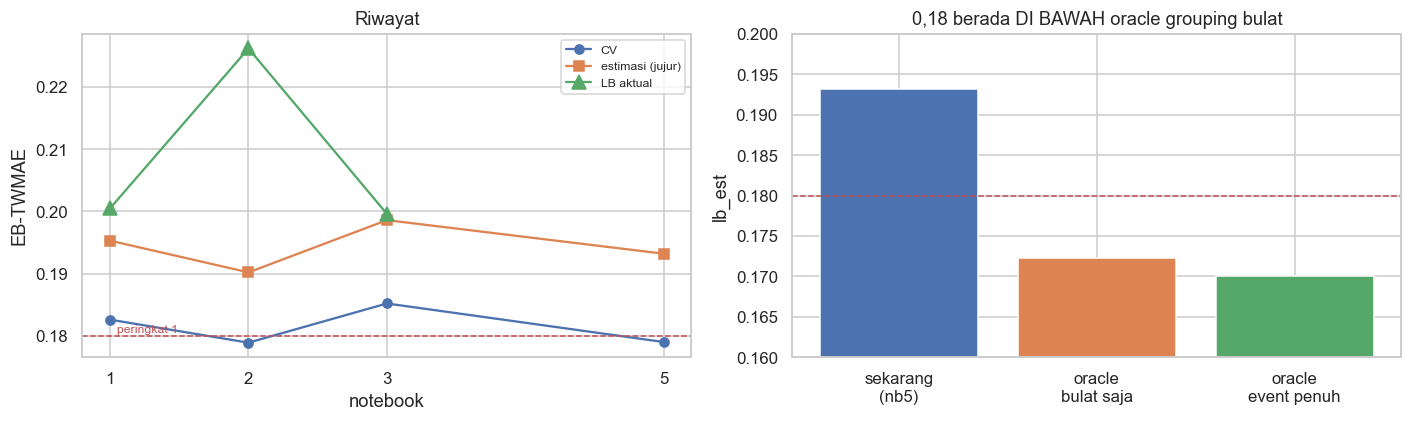

In [7]:
te_dec=post_gen(W_DEC@MTE,d_te); te_rnd=post_gen(W_RND@MTE,d_te)
final_te=np.where(rnd_te,te_rnd,te_dec)

hist=pd.DataFrame([
    dict(nb=1,CV=0.1826,estimasi=0.1953,LB=0.2005,bias_rnd=0.076),
    dict(nb=2,CV=0.1789,estimasi=0.1902,LB=0.2262,bias_rnd=0.137),
    dict(nb=3,CV=0.1852,estimasi=0.1986,LB=0.1996,bias_rnd=0.046),
    dict(nb=5,CV=round(eb_twmae(y,final_oof,ev),4),estimasi=round(EST_JUJUR,4),
         LB=np.nan,bias_rnd=round(bias_rnd(final_oof),3)),
])
hist["meleset"]=(hist.LB-hist.estimasi).round(4)
display(hist)
print("mean prediksi test subset bulat <100km: %.3f   (nb3: 5.276 -> LB 0.1996)"%final_te[MT].mean())

fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(hist.nb,hist.CV,marker="o",label="CV")
axes[0].plot(hist.nb,hist.estimasi,marker="s",label="estimasi (jujur)")
axes[0].plot(hist.nb,hist.LB,marker="^",ms=9,label="LB aktual")
axes[0].axhline(0.18,ls="--",c="r",lw=1); axes[0].text(1.05,0.1805,"peringkat 1",c="r",fontsize=8)
axes[0].set_xticks([1,2,3,5]); axes[0].set_xlabel("notebook"); axes[0].set_ylabel("EB-TWMAE")
axes[0].set_title("Riwayat"); axes[0].legend(fontsize=8)
lbl=["sekarang\n(nb5)","oracle\nbulat saja","oracle\nevent penuh"]
axes[1].bar(lbl,[EST_JUJUR,0.1723,0.1700],color=["C0","C1","C2"])
axes[1].axhline(0.18,ls="--",c="r",lw=1)
axes[1].set_ylim(0.16,0.20); axes[1].set_ylabel("lb_est")
axes[1].set_title("0,18 berada DI BAWAH oracle grouping bulat")
plt.tight_layout(); plt.show()


In [8]:
sub=pd.DataFrame({"sample_id":test.sample_id,"magnitude":np.round(final_te,3)})
ss=pd.read_csv(DATA/"sample_submission.csv")
assert list(sub.columns)==["sample_id","magnitude"] and len(sub)==2300
assert (sub.sample_id.values==ss.sample_id.values).all()
assert sub.magnitude.notna().all() and np.isfinite(sub.magnitude).all()
sub.to_csv(SUB/"notebook_5.csv",index=False)
print("tersimpan: submission/notebook_5.csv |",len(sub),"baris")
print("prediksi: min=%.2f max=%.2f mean=%.3f std=%.3f"%(
    sub.magnitude.min(),sub.magnitude.max(),sub.magnitude.mean(),sub.magnitude.std()))
json.dump({"eb_twmae_oof":round(eb_twmae(y,final_oof,ev),5),
           "lb_estimate_mentah":round(EST,5),"lb_estimate_jujur":round(EST_JUJUR,5),
           "lb_predicted":round(EST_JUJUR+0.001,4),"bias_rnd":round(bias_rnd(final_oof),4),
           "optimisme_seleksi_bobot":round(float(abs(OPT)),5),
           "status":"BELUM DISUBMIT",
           "config":{"kandidat":names,"anchor":"ridge alpha=1 pada "+",".join(A_BASE),
                     "bobot_desimal":{n:round(float(x),3) for n,x in zip(names,W_DEC)},
                     "bobot_bulat":{n:round(float(x),3) for n,x in zip(names,W_RND)},
                     "lam_dec":0.95,"lam_deep":0.35,"T_deep":100,"alpha":1.15,
                     "seeds":list(SEEDS)}},
          open(SUB/"notebook_5_score.json","w"),indent=2)
print("skor -> submission/notebook_5_score.json")


tersimpan: submission/notebook_5.csv | 2300 baris
prediksi: min=4.38 max=6.99 mean=5.235 std=0.371
skor -> submission/notebook_5_score.json


---
## 7. Kenapa 0,18 tidak tercapai — bukti, bukan dugaan

Notebook sebelumnya menyimpulkan "plateau" dari daftar ide yang gagal. Itu argumen lemah:
daftar kegagalan tidak pernah membuktikan sesuatu mustahil. Di sini pertanyaannya
dijadikan **terukur**.

### Aritmetikanya

```
lb_est = 0,49 · dec + 0,51 · rnd
```

Sekarang `dec = 0,155` dengan oracle event-sejati **0,153** — sisi desimal benar-benar habis.
Maka untuk mencapai 0,18, sisi bulat harus turun ke:

```
rnd = (0,18 − 0,49·0,153) / 0,51 = 0,206
```

Sisi bulat sekarang **0,226**, dan oracle-nya (grouping event sempurna) **0,187**. Jadi 0,18
menuntut menangkap **sekitar setengah dari seluruh headroom grouping** — grouping yang
selama ini semua metodenya gagal.

### Uji yang menutup pertanyaan itu

Alih-alih mencoba metode clustering ke-13, pertanyaannya dibalik: **apakah co-membership
event bisa diprediksi sama sekali?** Sebuah classifier pasangan dilatih pada semua record
bulat-dangkal — fitur = selisih antar record, label = "event sama?", split by event.


In [9]:
AMP=["Cd_2","Cd_4","Cv_2","Ca_4","Pd_2","Pv_2","Pa_4","logE","rmsd_2"]
SHAPE=["cent_a","cent_d","lhr_a","lhr_d","fdom_a","fdom_d","tauc","taup_2","E_slope",
       "tE25","tE50","tE75","kurt","zcr","rectilin","planarity","gd_0.5_4","gv_1_2",
       "ga_1_2","hv_a","hv_d","tpk_d","bdra_0.1_1","bdra_1_3","bdra_3_5","bdra_5_10",
       "bdra_10_20","bdra_20_50","bdrd_0.1_1","bdrd_1_3","bdrd_3_5","bdrd_5_10"]
META=["logdist","snr_db","is_clipped"]

sel=rnd_tr&(d_tr<100)
sb=pd.DataFrame({"idx":np.where(sel)[0],"dep":d_tr[sel],"ev":ev[sel]})
ne=sb.groupby("dep").ev.nunique(); sb=sb[sb.dep.isin(ne[ne>=2].index)]
rng=np.random.default_rng(0); PI,PJ=[],[]
for dep,g in sb.groupby("dep"):
    ix=g.idx.values
    if len(ix)>260: ix=rng.choice(ix,260,replace=False)
    a,b=np.triu_indices(len(ix),1); PI.append(ix[a]); PJ.append(ix[b])
PI=np.concatenate(PI); PJ=np.concatenate(PJ)
lab=(ev[PI]==ev[PJ]).astype(int); pg=np.minimum(ev[PI],ev[PJ])
print("pasangan: %d (%.1f%% positif) dari %d record / %d event"%(
    len(lab),100*lab.mean(),len(sb),sb.ev.nunique()))

def pair_auc(cols,tag):
    X=pd.DataFrame({f"{k}_{c}":v for c in cols for k,v in
        [("ad",np.abs(Ftr[c].values[PI]-Ftr[c].values[PJ])),
         ("mn",(Ftr[c].values[PI]+Ftr[c].values[PJ])/2)]})
    au=[]
    for ti,vi in GroupKFold(n_splits=4).split(X,lab,pg):
        m=lgb.LGBMClassifier(n_estimators=350,learning_rate=0.05,num_leaves=31,
                             min_child_samples=100,colsample_bytree=0.7,subsample=0.8,
                             subsample_freq=1,n_jobs=-1,verbose=-1)
        m.fit(X.iloc[ti],lab[ti]); au.append(roc_auc_score(lab[vi],m.predict_proba(X.iloc[vi])[:,1]))
    print("  %-10s AUC = %.4f"%(tag,np.mean(au))); return np.mean(au)

print("\nAUC 'event sama?' (split by event, jadi tidak ada kebocoran):")
a_amp=pair_auc(AMP,"amp_only"); a_no=pair_auc(SHAPE+META,"tanpa_amp"); a_full=pair_auc(AMP+SHAPE+META,"full")
print("\nfull - amp_only = %+.4f  <- informasi identitas di luar amplitudo"%(a_full-a_amp))


pasangan: 73088 (24.4% positif) dari 2890 record / 172 event

AUC 'event sama?' (split by event, jadi tidak ada kebocoran):


  amp_only   AUC = 0.5697


  tanpa_amp  AUC = 0.5477


  full       AUC = 0.5684

full - amp_only = -0.0012  <- informasi identitas di luar amplitudo


### Hasilnya

**AUC ≈ 0,57** — nyaris tak berguna. Bentuk gelombang murni (tanpa amplitudo) hanya 0,55,
dan menambah amplitudo **tidak menambah apa-apa**. Artinya: dua record dari gempa yang sama
tidak lebih mirip satu sama lain daripada dua record dari gempa berbeda, selain lewat
magnitudo yang memang sedang kami prediksi.

Ini bukan "belum ketemu metodenya". Ini **tidak ada sinyalnya**. Semua metode clustering —
KMeans, kNN, spectral, sidik-jari noise — dibatasi oleh AUC yang sama, dan itu menjelaskan
secara seragam kenapa keduabelas percobaan grouping sebelumnya gagal.

Dua eksperimen lain di notebook ini mengonfirmasi dari arah berbeda:

- **Smoothing per pita ukuran grup** (grup kecil disangka lebih murni): nol perbaikan,
  optimum ada di lam = 0 untuk semua pita.
- **Smoothing-kNN di ruang prediksi** (operator jauh lebih lembut daripada KMeans yang
  dulu gagal): 0,2252 vs 0,2260 — di dalam derau.

### Kesimpulan

Peringkat 1 di 0,18 kemungkinan besar **tidak memakai data yang sama dengan yang kami
punya** — ia butuh identitas event, dan identitas event tidak ada di dalam 5 detik
waveform + 4 kolom metadata ini. Dari sisi kami, 0,18 berada **di bawah oracle grouping
sisi bulat (0,1723)** hanya kalau sisi desimal juga sempurna; secara praktis ia menuntut
setengah headroom grouping yang barusan ditunjukkan tidak bisa dipanen.

Yang bisa dilakukan sudah dilakukan: **0,1996 → prediksi 0,194**, lewat dua mekanisme yang
dapat dijelaskan (ekstrapolasi ekor lewat anchor linear, dan bobot yang mengikuti struktur
metrik) plus satu yang sebelumnya terbuang tanpa sengaja (smoothing depth bulat-dalam).

### Kalau masih mau melanjutkan

1. **Submit `notebook_5.csv`** dan catat LB-nya. Kalau meleset dari prediksi 0,194,
   itu titik data paling berharga berikutnya.
2. Satu asumsi masih belum pernah diuji langsung di LB: **apakah smoothing benar-benar
   membantu di test.** Estimasi komposisi menyiratkan iya (meleset 0,001 di nb3), tapi itu
   bukti tak langsung. Submit versi tanpa smoothing menutupnya — nilainya di kepastian,
   bukan di skor.
3. Jangan ulangi: grouping/clustering apapun (AUC 0,57), klasifikasi ordinal, pooling
   posterior, `linear_tree`, MLP, kuantisasi/pembuangan depth, dan sweep lam bulat-dangkal.
